# 03 — Univariate Forecasting
Compare models using target-price lags. For each report metrics and generate actual-versus-predicted plots with approximate 95% prediction intervals.

In [20]:
from pathlib import Path
import sys, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Resolve project root from any nested notebook directory.
HERE = Path.cwd().resolve()
REPO_ROOT = next((p for p in [HERE, *HERE.parents] if (p / "src" / "features.py").exists()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Open this notebook somewhere inside the project folder containing src/features.py.")
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
from src.features import create_lagged_features

DATA_FILE = REPO_ROOT / "Data" / "lithium_consolidated_monthly.csv"
RESULTS_DIR = REPO_ROOT / "Results"
FIGURES_DIR = RESULTS_DIR / "figures"
TABLES_DIR = RESULTS_DIR / "tables"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "Selected lithium carbonate price (CNY/t)"
JAPAN_INDEX = "Japan, Import Prices, Yen Basis, Lithium Carbonates, Index, 2020 = 100"
RANDOM_STATE = 42
df = pd.read_csv(DATA_FILE)
df["Month"] = pd.to_datetime(df["Month"])
df = df.sort_values("Month").drop_duplicates("Month").set_index("Month").asfreq("MS")
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
print("Project root:", REPO_ROOT)
print("Data:", DATA_FILE)

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit, learning_curve

EXCLUDED = {
    TARGET, "Selected target source", "Lithium carbonate price (CNY/metric tonne)",
    "China spot lithium carbonate price (CNY/t) - CSV",
    "OLD - faulty cobalt settlement series (constant; excluded)",
    "China spot price open (CNY/t) - CSV", "China spot price high (CNY/t) - CSV",
    "China spot price low (CNY/t) - CSV", "China spot price volume (CSV)",
    "China spot price change (%) - CSV",
}
ALL_PREDICTORS = [c for c in df.select_dtypes(include=np.number).columns if c not in EXCLUDED]

def supervised_frame(horizon=1, n_lags=12, exog_cols=None):
    # Each row at origin t uses only observations through t-1.
    cols = [TARGET] + (list(exog_cols) if exog_cols else [])
    raw = df[cols].copy()
    lagged = create_lagged_features(raw, columns=cols, min_lag=1, max_lag=n_lags)
    y = df[TARGET].shift(-(horizon - 1)).rename("target")
    joined = lagged.join(y)
    # Retain valid labels even when one or more optional predictors are missing.
    joined = joined.dropna(subset=["target"])
    # Re-label rows by the month being forecast, not the feature-origin month.
    target_index = joined.index + pd.offsets.MonthBegin(horizon - 1)
    joined.index = target_index
    return joined.drop(columns="target"), joined["target"]

def chronological_split(X, y, test_fraction=0.20):
    cut = int(len(X) * (1-test_fraction))
    return X.iloc[:cut], X.iloc[cut:], y.iloc[:cut], y.iloc[cut:]

def model_bank():
    return {
        "Linear Regression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LinearRegression()),
        "KNN": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), KNeighborsRegressor(n_neighbors=5)),
        "SVR": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), SVR(C=10, epsilon=0.1)),
        "Random Forest": make_pipeline(SimpleImputer(strategy="median"), RandomForestRegressor(n_estimators=250, min_samples_leaf=2, random_state=RANDOM_STATE)),
        "Gradient Boosting": make_pipeline(SimpleImputer(strategy="median"), GradientBoostingRegressor(random_state=RANDOM_STATE)),
    }

def score(y, pred):
    return {"MAE": mean_absolute_error(y, pred),
            "RMSE": mean_squared_error(y, pred)**0.5,
            "R2": r2_score(y, pred)}

def calibration_residuals(X_train, y_train, model_name, calibration_fraction=0.20):
    """Out-of-sample residuals from a trailing calibration segment within training data."""
    cut = int(len(X_train) * (1-calibration_fraction))
    X_fit, X_cal = X_train.iloc[:cut], X_train.iloc[cut:]
    y_fit, y_cal = y_train.iloc[:cut], y_train.iloc[cut:]
    if len(X_fit) < 20 or len(X_cal) < 5:
        raise ValueError("Not enough training observations for residual calibration.")
    cal_model = model_bank()[model_name]
    cal_model.fit(X_fit, y_fit)
    return (y_cal - cal_model.predict(X_cal)).to_numpy()

def moving_block_sample(values, n, block=3, rng=None):
    rng = np.random.default_rng(RANDOM_STATE) if rng is None else rng
    values = np.asarray(values)
    if len(values) == 0:
        raise ValueError("Residual calibration set is empty.")
    out = []
    while len(out) < n:
        start = int(rng.integers(0, max(1, len(values)-block+1)))
        out.extend(values[start:start+block])
    return np.asarray(out[:n])

def prediction_interval(pred, residuals, n_boot=1500, block=3, seed=42):
    rng = np.random.default_rng(seed)
    sims = np.vstack([pred + moving_block_sample(residuals, len(pred), block, rng) for _ in range(n_boot)])
    return np.quantile(sims, 0.025, axis=0), np.quantile(sims, 0.975, axis=0)

def plot_forecast(y_test, pred, lower, upper, title, filename, zoom_n=36):
    fig, ax = plt.subplots(figsize=(13,5))
    ax.plot(y_test.index, y_test.values, label="Observed", linewidth=2)
    ax.plot(y_test.index, pred, label="Central prediction", linewidth=1.7)
    ax.plot(y_test.index, upper, color="tab:red", linewidth=1, label="Upper prediction")
    ax.plot(y_test.index, lower, color="tab:red", linewidth=1, label="Lower prediction")
    ax.fill_between(y_test.index, lower, upper, color="tab:red", alpha=.13, label="95% prediction interval")
    ax.set(title=title, xlabel="Target month", ylabel="Lithium carbonate price (CNY/tonne)")
    ax.grid(alpha=.25); ax.legend(); plt.tight_layout()
    fig.savefig(FIGURES_DIR / filename, dpi=180); plt.show()
    if len(y_test) > zoom_n:
        fig, ax = plt.subplots(figsize=(13,5))
        ax.plot(y_test.index[-zoom_n:], y_test.values[-zoom_n:], label="Observed", linewidth=2)
        ax.plot(y_test.index[-zoom_n:], pred[-zoom_n:], label="Central prediction")
        ax.fill_between(y_test.index[-zoom_n:], lower[-zoom_n:], upper[-zoom_n:], color="tab:red", alpha=.16, label="95% prediction interval")
        ax.set(title=title + " — zoomed view", xlabel="Target month", ylabel="CNY/tonne")
        ax.grid(alpha=.25); ax.legend(); plt.tight_layout()
        fig.savefig(FIGURES_DIR / filename.replace(".png", "_zoomed.png"), dpi=180); plt.show()

def plot_learning_curve(model, X, y, title, filename):
    cv = TimeSeriesSplit(n_splits=4)
    sizes = np.linspace(.45, 1.0, 4)
    train_sizes, train_scores, val_scores = learning_curve(
        model, X, y, cv=cv, train_sizes=sizes,
        scoring="neg_mean_squared_error", n_jobs=None
    )
    train_rmse = np.sqrt(-train_scores).mean(axis=1)
    val_rmse = np.sqrt(-val_scores).mean(axis=1)
    fig, ax = plt.subplots(figsize=(8,5))
    ax.plot(train_sizes, train_rmse, marker="o", label="Training RMSE")
    ax.plot(train_sizes, val_rmse, marker="o", label="Validation RMSE")
    ax.set(title=title, xlabel="Number of training observations", ylabel="RMSE")
    ax.grid(alpha=.25); ax.legend(); plt.tight_layout()
    fig.savefig(FIGURES_DIR / filename, dpi=180); plt.show()
    return pd.DataFrame({"Training observations":train_sizes,"Training RMSE":train_rmse,"Validation RMSE":val_rmse})

Project root: /home/schmidlucy/Lucy-Schmid.github.io
Data: /home/schmidlucy/Lucy-Schmid.github.io/Data/lithium_consolidated_monthly.csv


## Fit models for 1-, 3-, 6-, and 12-month horizons

In [21]:
HORIZONS=[1,3,6,12]
rows=[]; store={}
for h in HORIZONS:
    X,y=supervised_frame(horizon=h,n_lags=12,exog_cols=None)
    Xtr,Xte,ytr,yte=chronological_split(X,y)
    for name,model in model_bank().items():
        model.fit(Xtr,ytr); pred=model.predict(Xte)
        rows.append({"Horizon":h,"Model":name,**score(yte,pred)})
        store[(h,name)]=(Xtr,Xte,ytr,yte,pred)
results=pd.DataFrame(rows).sort_values(["Horizon","RMSE"])
display(results); results.to_csv(TABLES_DIR/"univariate_model_comparison.csv",index=False)

,Horizon,Model,MAE,RMSE,R2
3,1,Random Forest,19384.135720,28047.153105,0.762838
4,1,Gradient Boosting,25738.346988,39795.006755,0.522554
0,1,Linear Regression,27361.478327,43366.078775,0.433020
1,1,KNN,43263.488095,70710.311296,-0.507414
2,1,SVR,75396.922908,94865.582870,-1.713216
9,3,Gradient Boosting,51090.795953,82100.382036,-1.032158
8,3,Random Forest,52373.039498,85742.343120,-1.216449
7,3,SVR,74882.346286,94471.983136,-1.690749
6,3,KNN,68070.321429,96487.933870,-1.806810
5,3,Linear Regression,63423.358292,97317.204186,-1.855264


## RMSE by model and forecast horizon

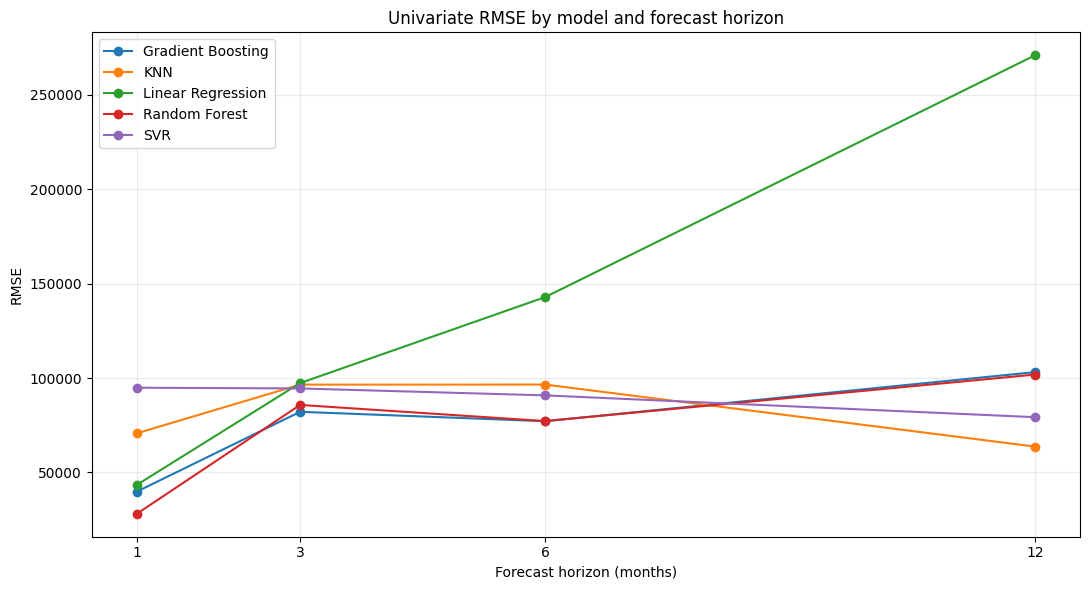

In [22]:
fig,ax=plt.subplots(figsize=(11,6))
for name,g in results.groupby("Model"): ax.plot(g.Horizon,g.RMSE,marker="o",label=name)
ax.set(title="Univariate RMSE by model and forecast horizon",xlabel="Forecast horizon (months)",ylabel="RMSE")
ax.set_xticks(HORIZONS); ax.grid(alpha=.25); ax.legend()
plt.tight_layout(); fig.savefig(FIGURES_DIR/"06_univariate_rmse_by_horizon.png",dpi=180); plt.show()

## Best model: one-month prediction interval

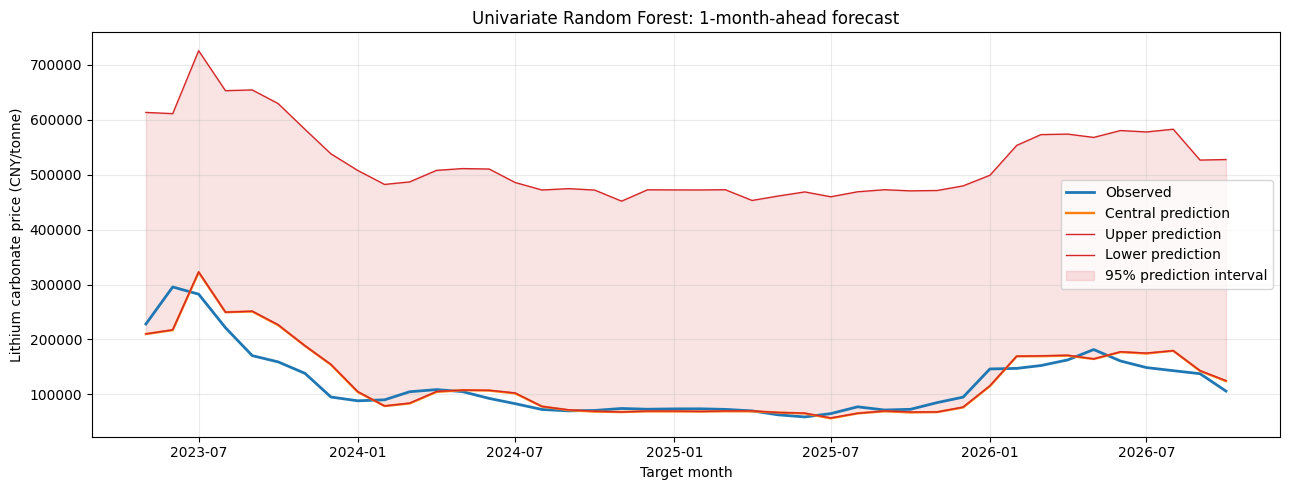

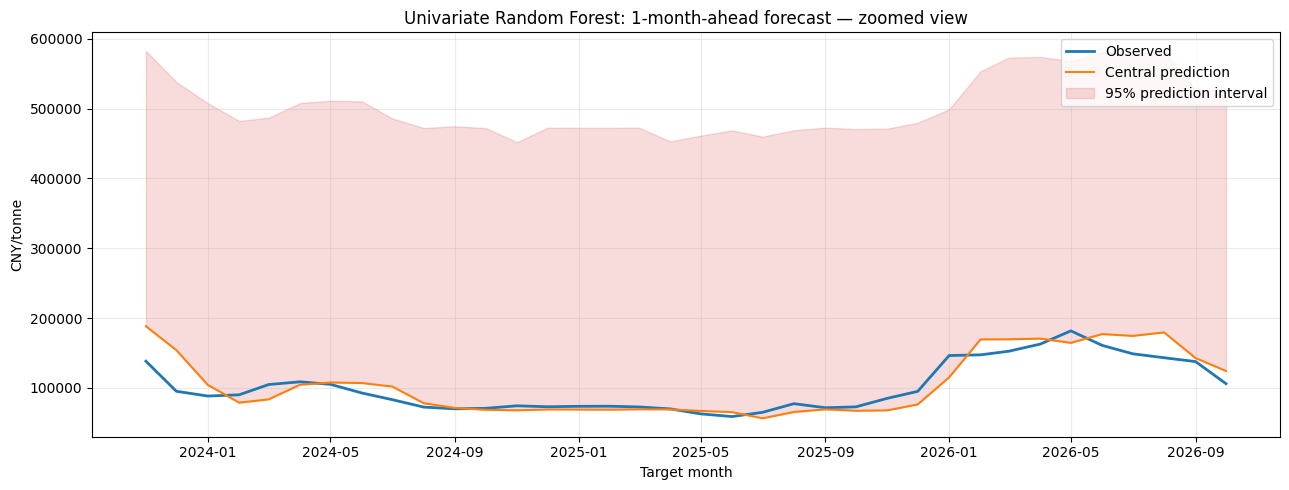

Empirical test interval coverage: 0.452


In [23]:
best_name=results[results.Horizon==1].sort_values("RMSE").iloc[0]["Model"]
Xtr,Xte,ytr,yte,pred=store[(1,best_name)]
resid=calibration_residuals(Xtr,ytr,best_name)
lower,upper=prediction_interval(pred,resid,n_boot=1500,block=3)
plot_forecast(yte,pred,lower,upper,f"Univariate {best_name}: 1-month-ahead forecast","07_univariate_forecast_interval.png")
interval_coverage=np.mean((yte.values>=lower)&(yte.values<=upper))
print("Empirical test interval coverage:",round(interval_coverage,3))
pd.DataFrame({"actual":yte,"prediction":pred,"lower_95":lower,"upper_95":upper}).to_csv(TABLES_DIR/"univariate_1month_predictions_and_intervals.csv")

## Learning curve: best one-month model

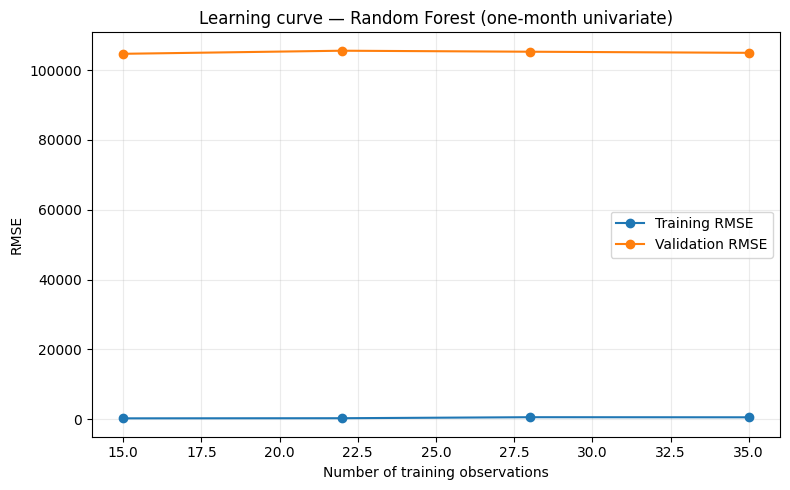

,Training observations,Training RMSE,Validation RMSE
0,15,281.826476,104681.879132
1,22,317.811982,105564.811344
2,28,605.716494,105277.996023
3,35,578.860952,104960.954515


In [24]:
X,y=supervised_frame(horizon=1,n_lags=12,exog_cols=None)
Xtr,_,ytr,_=chronological_split(X,y)
learning=plot_learning_curve(model_bank()[best_name],Xtr,ytr,
    f"Learning curve — {best_name} (one-month univariate)","08_univariate_learning_curve.png")
display(learning); learning.to_csv(TABLES_DIR/"univariate_learning_curve.csv",index=False)

## Residual diagnostics

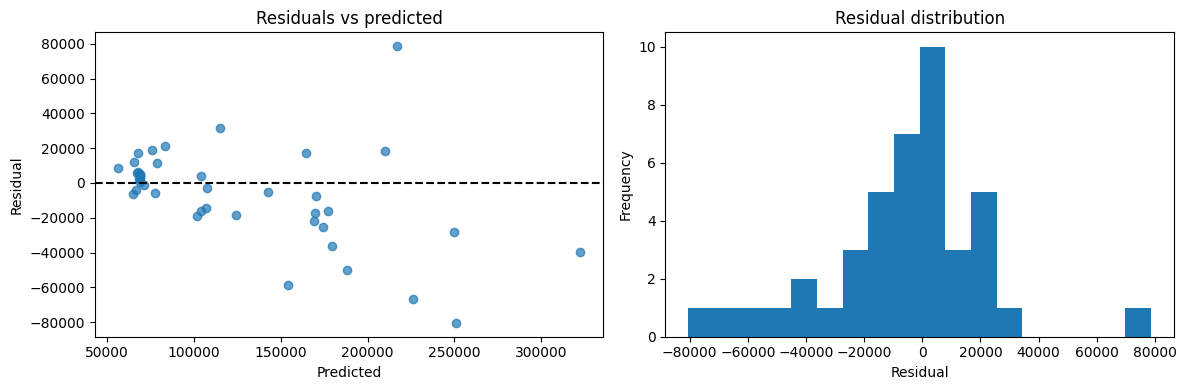

In [25]:
resid=yte.values-pred
fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].scatter(pred,resid,alpha=.7); axs[0].axhline(0,color="black",linestyle="--")
axs[0].set(title="Residuals vs predicted",xlabel="Predicted",ylabel="Residual")
axs[1].hist(resid,bins=18); axs[1].set(title="Residual distribution",xlabel="Residual",ylabel="Frequency")
plt.tight_layout(); fig.savefig(FIGURES_DIR/"09_univariate_residual_diagnostics.png",dpi=180); plt.show()

## Actual vs predicted scatter

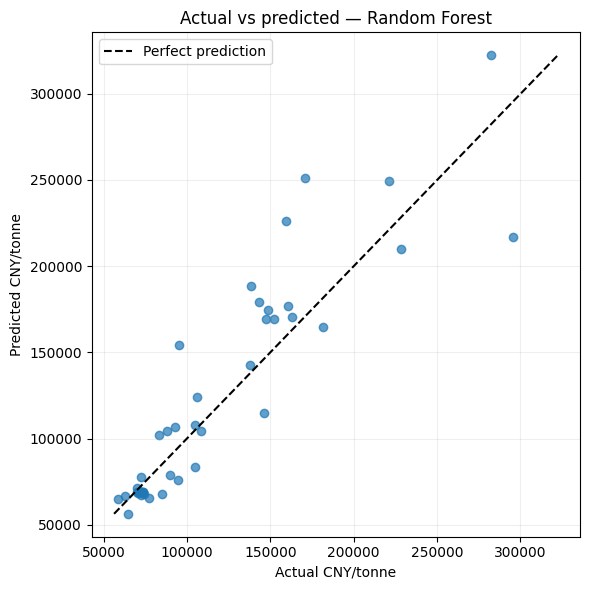

In [26]:
fig,ax=plt.subplots(figsize=(6,6)); ax.scatter(yte.values,pred,alpha=.7)
lo=min(yte.min(),pred.min()); hi=max(yte.max(),pred.max()); ax.plot([lo,hi],[lo,hi],"k--",label="Perfect prediction")
ax.set(title=f"Actual vs predicted — {best_name}",xlabel="Actual CNY/tonne",ylabel="Predicted CNY/tonne")
ax.legend(); ax.grid(alpha=.2); plt.tight_layout(); fig.savefig(FIGURES_DIR/"10_univariate_actual_predicted_scatter.png",dpi=180); plt.show()